# CNN on MNIST (PyTorch): Convergence, Random Labels & Permutation Invariance

Building and training a convolutional neural network on MNIST in PyTorch, then stress-testing it: visualizing convergence, checking what happens when it's trained on randomly-assigned labels, and testing whether it still performs when the pixels in every image are shuffled the same way.

In [2]:
from IPython.display import Math
from IPython.display import Latex

import numpy as np
import os
import struct

from sklearn.metrics import classification_report,confusion_matrix
from sklearn.neural_network import MLPClassifier

import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

torch.manual_seed(2501)

----------------
----------------
----------------

## <font color='blue'> **Section 1.** Visualizing convergence. </font>

This section extends the training loop to record, at every epoch, the test loss, training accuracy, and test accuracy — without letting the test set influence the weight updates — then runs the model for 20 epochs and plots the loss and accuracy curves to visualize convergence.

In [11]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 64

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [12]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

# Added - Initialize Var - Num Epochs - Default: 20
num_epochs = 20

# Added - Initialize Vars - Train / Test Accuracies & Losses (Each Epoch)
train_losses = []
test_losses = []
train_accs = []
test_accs = []

In [15]:
for epoch in range(num_epochs):  # loop over the dataset multiple times

    running_loss = 0.0
    # Added - Initialize Vars & Start Training
    net.train()
    train_correct_preds = 0
    train_total_preds = 0

    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        # Added - pull predicted labels - calculate # correct
        _, predicted = torch.max(outputs.data, 1)
        train_total_preds += labels.size(0)
        train_correct_preds += (predicted == labels).sum().item()

        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0
    # Added - calculate accuracy & loss stats for training
    avg_train_loss = running_loss / len(trainloader)
    train_acc = 100.0 * train_correct_preds / train_total_preds

    # Added - append loss and accuracy of epoch into lists
    train_losses.append(avg_train_loss)
    train_accs.append(train_acc)

    print('Finished Training')

    # Added - Testing - Initialize Variables
    net.eval()
    running_loss = 0.0
    test_correct_preds = 0
    test_total_preds = 0

    with torch.no_grad():
      for i, data in enumerate(testloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        test_total_preds += labels.size(0)
        test_correct_preds += (predicted == labels).sum().item()
    # Added - calculate accuracy & loss stats for testing
    avg_test_loss = running_loss / len(testloader)
    test_acc = 100.0 * test_correct_preds / test_total_preds
    # Added - append loss and accuracy of epoch into lists
    test_losses.append(avg_test_loss)
    test_accs.append(test_acc)
    # Print Statistics
    print(f'Epoch {epoch+1}: '
          f'Training Accuracy: {train_acc:.2f}% '
          f'Test Loss: {avg_test_loss:.2f}% '
          f'Test Accuracy: {test_acc:.2f}%')

Finished Training
Epoch 1: Training Accuracy: 21.08%Test Loss: 2.01%Test Accuracy: 28.07%
Finished Training
Epoch 2: Training Accuracy: 33.42%Test Loss: 1.72%Test Accuracy: 37.43%
Finished Training
Epoch 3: Training Accuracy: 39.68%Test Loss: 1.58%Test Accuracy: 41.69%
Finished Training
Epoch 4: Training Accuracy: 43.04%Test Loss: 1.51%Test Accuracy: 44.66%
Finished Training
Epoch 5: Training Accuracy: 45.94%Test Loss: 1.45%Test Accuracy: 46.85%
Finished Training
Epoch 6: Training Accuracy: 48.22%Test Loss: 1.40%Test Accuracy: 49.44%
Finished Training
Epoch 7: Training Accuracy: 50.12%Test Loss: 1.36%Test Accuracy: 50.98%
Finished Training
Epoch 8: Training Accuracy: 51.56%Test Loss: 1.32%Test Accuracy: 52.02%
Finished Training
Epoch 9: Training Accuracy: 53.31%Test Loss: 1.30%Test Accuracy: 53.57%
Finished Training
Epoch 10: Training Accuracy: 54.54%Test Loss: 1.29%Test Accuracy: 53.58%
Finished Training
Epoch 11: Training Accuracy: 56.03%Test Loss: 1.24%Test Accuracy: 55.34%
Finished

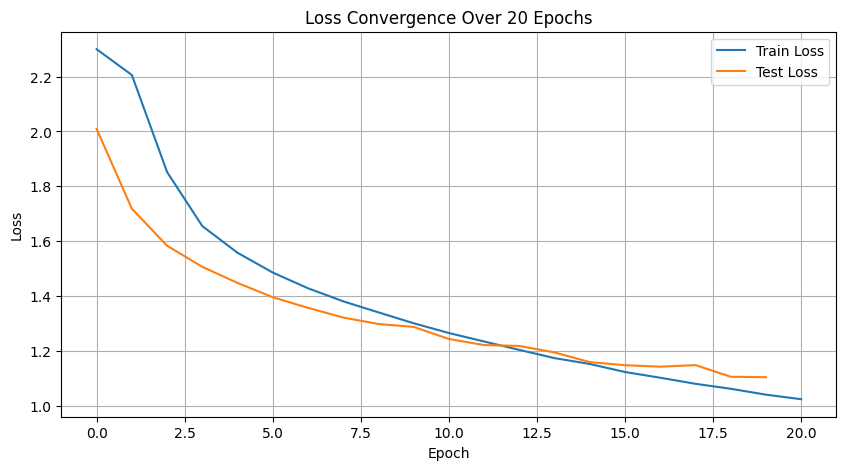

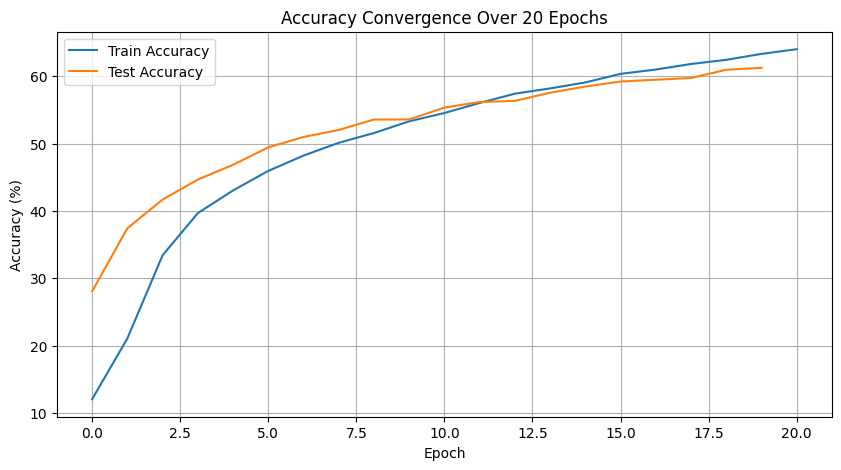

In [16]:
# Question 1-D

# Loss Curves
plt.figure(figsize=(10,5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title("Loss Convergence Over 20 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy Curves
plt.figure(figsize=(10,5))
plt.plot(train_accs, label='Train Accuracy')
plt.plot(test_accs, label='Test Accuracy')
plt.title("Accuracy Convergence Over 20 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()


------------------------------
------------------------------
------------------------------

## <font color='blue'> **Section 2.** Learning random labels. </font>

Reusing the same training setup, this section replaces the real training labels with randomly-assigned ones and trains for 40 epochs, tracking training accuracy and comparing the final result against the accuracy expected from a random baseline.

100%|██████████| 170M/170M [00:01<00:00, 93.0MB/s]


Epoch 1: Training Accuracy: 10.11% Training Loss: 2.3430%
Epoch 2: Training Accuracy: 10.70% Training Loss: 2.3048%
Epoch 3: Training Accuracy: 10.77% Training Loss: 2.3031%
Epoch 4: Training Accuracy: 10.97% Training Loss: 2.3019%
Epoch 5: Training Accuracy: 11.10% Training Loss: 2.3009%
Epoch 6: Training Accuracy: 11.14% Training Loss: 2.3001%
Epoch 7: Training Accuracy: 11.30% Training Loss: 2.2994%
Epoch 8: Training Accuracy: 11.55% Training Loss: 2.2985%
Epoch 9: Training Accuracy: 11.47% Training Loss: 2.2977%
Epoch 10: Training Accuracy: 11.86% Training Loss: 2.2970%
Epoch 11: Training Accuracy: 11.96% Training Loss: 2.2960%
Epoch 12: Training Accuracy: 12.02% Training Loss: 2.2951%
Epoch 13: Training Accuracy: 12.01% Training Loss: 2.2941%
Epoch 14: Training Accuracy: 12.15% Training Loss: 2.2930%
Epoch 15: Training Accuracy: 12.31% Training Loss: 2.2922%
Epoch 16: Training Accuracy: 12.59% Training Loss: 2.2909%
Epoch 17: Training Accuracy: 12.75% Training Loss: 2.2898%
Epoch 

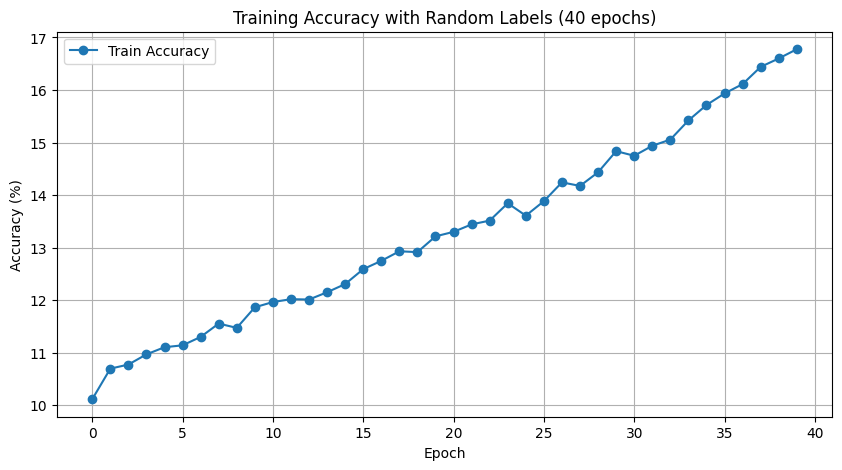

Final training accuracy: 16.776


In [17]:
# Question 2-A
# Initialize Variables
num_classes = 10
num_epochs = 40

# Initialize CIFAR-10 Dataset
trainset = torchvision.datasets.CIFAR10(
    root='/.data', train=True, download=True, transform=transform
)
# Generate Random Labels For the 10 Classes
random_labels = torch.randint(0, num_classes, (len(trainset),))
# Replace Correct Labels with Randomly Generated Labels
trainset.targets = random_labels.tolist()
# Initialize the Dataloader
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2
)

# Initialize List to Store Training Accuracies
train_accs = []

for epoch in range(num_epochs):  # loop over the dataset multiple times
    # Initialize Variables - Setting to Training Mode
    running_loss = 0.0

    net.train()
    train_correct_preds = 0
    train_total_preds = 0

    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # update loss
        running_loss += loss.item()
        # pull predictions for each image - calculate # correct
        _, predicted = torch.max(outputs.data, 1)
        train_total_preds += labels.size(0)
        train_correct_preds += (predicted == labels).sum().item()

        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0
    # calculate epoch-level loss and accuracy
    avg_train_loss = running_loss / len(trainloader)
    train_acc = 100.0 * train_correct_preds / train_total_preds
    # append accuracy to list of training accuracies
    train_accs.append(train_acc)
    # print epoch statistics
    print(f'Epoch {epoch+1}: '
          f'Training Accuracy: {train_acc:.2f}% '
          f'Training Loss: {avg_train_loss:.4f}%')

# plot accuracy curve
plt.figure(figsize=(10,5))
plt.plot(train_accs, label='Train Accuracy', marker='o')
plt.title("Training Accuracy with Random Labels (40 epochs)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

# Question 2-B
# Print Accuracy Of Final Epoch
print("Final training accuracy:", train_accs[-1], "%")

**Expected accuracy under random guessing:**
<br>
With 10 classes that the true label could possibly belong to, it would result in a 10% expected accuracy. If the baseline model just uniformly and randomly guesses the class of each data point, it would be correct 10% of the time. Short-term accuracy may fluctuate from 10%, but over the long run it will approach 10%.

------------------------------
------------------------------
------------------------------

## <font color='blue'> **Section 3.** Modifying the model for MNIST. </font>

This section adapts the CNN from the synthetic/random-label setup to the standard MNIST dataset: building MNIST dataloaders, adjusting the model's internal layer sizes to fit MNIST's input dimensions, and reporting training and test accuracy after 10 epochs.

In [3]:
# Question 3-A
# Initialize Batch Size
batch_size = 64

# Define Tranformations To Apply - Convert to PyTorch Tensor & Normalize
transform_mnist = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Load MNIST dataset - Train
trainset_mnist = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform_mnist
)
# Create Training DataLoader
trainloader_mnist = torch.utils.data.DataLoader(
    trainset_mnist, batch_size=batch_size, shuffle=True, num_workers=2
)
# Load MNIST dataset - Test
testset_mnist = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform_mnist
)
# Create Testing DataLoader
testloader_mnist = torch.utils.data.DataLoader(
    testset_mnist, batch_size=batch_size, shuffle=False, num_workers=2
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 36.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.09MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.17MB/s]


In [4]:
# Question 3-B
class MNISTNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)      # 1 input channel (MNIST), 6 filters, 5x5
        self.pool  = nn.MaxPool2d(2, 2)      # Reduce Dimensions by 2
        self.conv2 = nn.Conv2d(6, 16, 5)     # 6 -> 16 filters, 5x5

        # For 28x28:
        # conv1: 28 -> 24 -> pool -> 12
        # conv2: 12 -> 8 -> pool -> 4
        # => 16 feature maps of size 4x4 -> 16*4*4 = 256
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)         # 10 classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)              # flatten all dims except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

net = MNISTNet()

In [6]:
# Question 3-C
# Initialize Variables
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9)

num_epochs = 10
train_accs = []
test_accs = []

for epoch in range(num_epochs):
  # Initialize Variables - Set to Training Mode
  net.train()
  train_correct_preds = 0
  train_total_preds = 0

  for i, data in enumerate(trainloader_mnist, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        # pull predictions for dataset - calculate # of correct predictions
        _, predicted = torch.max(outputs.data, 1)
        train_total_preds += labels.size(0)
        train_correct_preds += (predicted == labels).sum().item()
  # calculate training accuracy - append to list of training accuracies
  train_acc = 100.0 * train_correct_preds / train_total_preds
  train_accs.append(train_acc)
  # Initialize Variables - Set to Testing / Eval Mode
  net.eval()
  test_correct_preds = 0
  test_total_preds = 0

  with torch.no_grad():
    for i, data in enumerate(testloader_mnist, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward
        outputs = net(inputs)
        loss = criterion(outputs, labels)

        # pull predictions for dataset - calculate # of correct predictions
        _, predicted = torch.max(outputs.data, 1)
        test_total_preds += labels.size(0)
        test_correct_preds += (predicted == labels).sum().item()
    # calculate accuracy stat for testing
    test_acc = 100.0 * test_correct_preds / test_total_preds
    # append accuracy of epoch into lists
    test_accs.append(test_acc)
    # print epoch statistics
    print(f'Epoch {epoch+1}: '
          f'Training Accuracy: {train_acc:.2f}% '
          f'Test Accuracy: {test_acc:.2f}%')
# Print Accuracy of Training & Testing After 10 Epochs
print("Final training accuracy after 10 epochs: ", train_accs[-1])
print("Final test accuracy after 10 epochs: ", test_accs[-1])

Epoch 1: Training Accuracy: 84.66% Test Accuracy: 97.23%
Epoch 2: Training Accuracy: 97.58% Test Accuracy: 98.40%
Epoch 3: Training Accuracy: 98.43% Test Accuracy: 98.63%
Epoch 4: Training Accuracy: 98.68% Test Accuracy: 98.72%
Epoch 5: Training Accuracy: 99.02% Test Accuracy: 98.72%
Epoch 6: Training Accuracy: 99.14% Test Accuracy: 98.93%
Epoch 7: Training Accuracy: 99.24% Test Accuracy: 98.94%
Epoch 8: Training Accuracy: 99.34% Test Accuracy: 98.70%
Epoch 9: Training Accuracy: 99.39% Test Accuracy: 98.74%
Epoch 10: Training Accuracy: 99.52% Test Accuracy: 99.07%
Final training accuracy after 10 epochs:  99.52166666666666
Final test accuracy after 10 epochs:  99.07


------------------------------
------------------------------
------------------------------

## <font color='blue'> **Section 4.** MNIST on randomly permuted images. </font>

This section tests whether the CNN's performance depends on the spatial structure of the image, by applying the same random pixel permutation to every image in the dataset and retraining the MNIST model from the previous section on the permuted data, comparing training and test accuracy at 10 and 20 epochs against the unpermuted result.

In [7]:
# Question 4-A
# create random permutation of all 28 x 28 pixels
permutation = torch.randperm(28 * 28)
# create PyTorch transformation - flatten 28 x 28 MNIST image to 1D vector - apply permutation -
# then convert back to 28 x 28 image from 1D vector
permute_tranformation = transforms.Lambda(
    lambda x: x.view(-1)[permutation].view(1, 28, 28)
)
# create transformation pipeline - convert to tensor - apply 28 x 28 permutation - normalize values
transformed_mnist = transforms.Compose([
    transforms.ToTensor(),
    permute_tranformation,
    transforms.Normalize((0.5,), (0.5,))
])

In [8]:
# Initialize Var - batch_size
batch_size = 64
# Load MNIST dataset - Train - Apply Permutation
trainset_mnist = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transformed_mnist
)
# Load MNIST dataset - Test - Apply Permutation
testset_mnist = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transformed_mnist
)
# Create Training DataLoader
trainloader_mnist = torch.utils.data.DataLoader(
    trainset_mnist, batch_size=batch_size, shuffle=True, num_workers=0
)
# Create Testing DataLoader
testloader_mnist = torch.utils.data.DataLoader(
    testset_mnist, batch_size=batch_size, shuffle=False, num_workers=0
)

In [9]:
# Question 4-B, C
# Initialize Variables
net = MNISTNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9)

num_epochs = 20
train_accs = []
test_accs = []
# Loop for Specified # of Epochs
for epoch in range(num_epochs):

    # Initialize Variables - Set to Training Mode
    net.train()
    train_correct_preds = 0
    train_total_preds = 0

    for i, data in enumerate(trainloader_mnist, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        # pull predictions for dataset - calculate # of correct predictions
        _, predicted = torch.max(outputs.data, 1)
        train_total_preds += labels.size(0)
        train_correct_preds += (predicted == labels).sum().item()

    # calculate training accuracy - append to list of training accuracies
    train_acc = 100.0 * train_correct_preds / train_total_preds
    train_accs.append(train_acc)

    # Initialize Variables - Set to Testing / Eval Mode
    net.eval()
    test_correct_preds = 0
    test_total_preds = 0

    with torch.no_grad():
      for i, data in enumerate(testloader_mnist, 0):
          # get the inputs; data is a list of [inputs, labels]
          inputs, labels = data

          # zero the parameter gradients
          optimizer.zero_grad()

          # forward
          outputs = net(inputs)
          loss = criterion(outputs, labels)

          # pull predictions for dataset - calculate # of correct predictions
          _, predicted = torch.max(outputs.data, 1)
          test_total_preds += labels.size(0)
          test_correct_preds += (predicted == labels).sum().item()
    # calculate accuracy stat for testing
    test_acc = 100.0 * test_correct_preds / test_total_preds
    # append accuracy of epoch into lists
    test_accs.append(test_acc)
    # print epoch statistics
    print(f'Epoch {epoch+1}: '
          f'Training Accuracy: {train_acc:.2f}% '
          f'Test Accuracy: {test_acc:.2f}%')

# Print Accuracies For After 10th Epoch & After 20th Epoch
print("\nAfter 10 epochs:")
print("  Train accuracy: ", train_accs[9])
print("  Test  accuracy: ", test_accs[9])

print("\nAfter 20 epochs:")
print("  Train accuracy: ", train_accs[19])
print("  Test  accuracy: ", test_accs[19])

Epoch 1: Training Accuracy: 68.71% Test Accuracy: 91.27%
Epoch 2: Training Accuracy: 92.00% Test Accuracy: 92.61%
Epoch 3: Training Accuracy: 93.78% Test Accuracy: 93.54%
Epoch 4: Training Accuracy: 94.65% Test Accuracy: 93.97%
Epoch 5: Training Accuracy: 95.36% Test Accuracy: 95.22%
Epoch 6: Training Accuracy: 95.89% Test Accuracy: 95.07%
Epoch 7: Training Accuracy: 96.41% Test Accuracy: 95.29%
Epoch 8: Training Accuracy: 96.93% Test Accuracy: 94.70%
Epoch 9: Training Accuracy: 97.11% Test Accuracy: 95.34%
Epoch 10: Training Accuracy: 97.45% Test Accuracy: 95.28%
Epoch 11: Training Accuracy: 97.52% Test Accuracy: 95.23%
Epoch 12: Training Accuracy: 97.91% Test Accuracy: 94.87%
Epoch 13: Training Accuracy: 97.99% Test Accuracy: 95.21%
Epoch 14: Training Accuracy: 98.18% Test Accuracy: 95.72%
Epoch 15: Training Accuracy: 98.37% Test Accuracy: 94.64%
Epoch 16: Training Accuracy: 98.43% Test Accuracy: 95.27%
Epoch 17: Training Accuracy: 98.55% Test Accuracy: 95.18%
Epoch 18: Training Accu